# Seminar 7 · DDPM and DDIM

**Deep Generative Models · MIPT / ШАД (YSDA) · 5 November 2026**

Adapted from Seminar 9 of the 2025 MIPT / YSDA course.

[Previous seminar: score matching and NCSN](../seminar6/seminar6.ipynb)

[Hands-on MNIST notebook](seminar7_ddpm_mnist.ipynb) · [Run practice in Colab](https://colab.research.google.com/github/r-isachenko/2026-DGM-MIPT-YSDA-course/blob/main/seminars/seminar7/seminar7_ddpm_mnist.ipynb)

Train a small DDPM from scratch, then compare DDPM and DDIM using the same weights and initial noise. A visual recap follows the theory.

## Plan

1. Define the forward process and its noisy marginals.
2. View diffusion as a VAE and derive the training objective.
3. Predict noise and sample with DDPM.
4. Reuse the noise predictor for DDIM and fewer sampling steps.

## DDPM

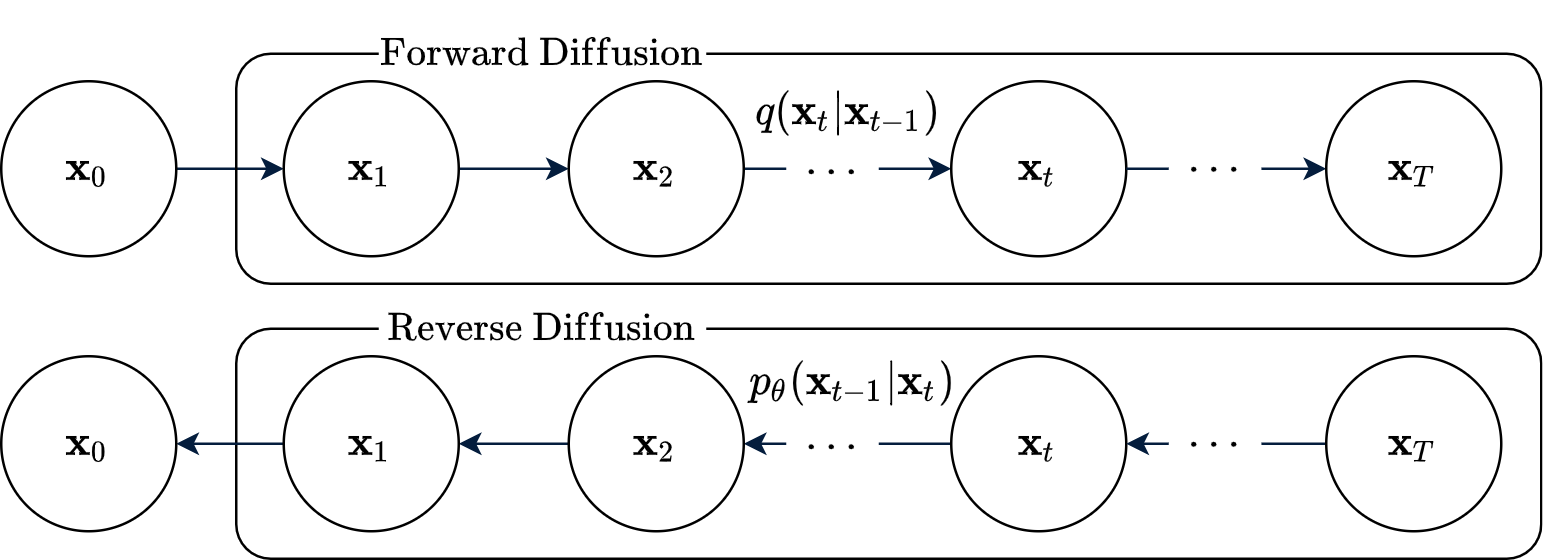

In [ ]:
# Saved figure from the previous semester; no execution needed.


Diffusion models are latent variable models of the form
$$
p_\theta(x_0) := \int p_\theta(x_0 | z) p_\theta(z) dz,
$$
where $z = (x_1, \dots, x_T)$ are latents of the same dimensionality as the data $x_0 \sim q(x_0)$.

## **Question 1.** How can we define encoder in such VAE?

In this case, the most convenient way to build an encoder is to fix a Markov chain that gradually adds Gaussian noise to the data, according to  
$$
    q(z | x) = q(x_1, \dots, x_T | x_0) = \prod_{t = 1}^T q(x_t | x_{t - 1}),
$$
where
$$
q(x_t \mid x_{t-1}) := \mathcal{N}\left(x_t; \sqrt{1 - \beta_t} \, x_{t-1}, \beta_t \, \mathbf{I}\right)
$$

**Sub-question:**  
Why do we need to add a Gaussian forward process?

As $\bar\alpha_T=\prod_{t=1}^T(1-\beta_t)$ approaches zero,
$$
q(x_T\mid x_0)=\mathcal N\!\left(\sqrt{\bar\alpha_T}x_0,(1-\bar\alpha_T)I\right)\approx\mathcal N(0,I).
$$
The signal fades while the noise variance approaches one. This motivates the simple prior $p(x_T)=\mathcal N(0,I)$. At finite $T$, the match is approximate and depends on the noise schedule.

## **Question 2.** Why do we need Markov property?

The Markov property of $q(x_t \mid x_{t-1})$ is mainly due to the simplicity it provides in constructing the forward process. Now, we have an analytic formula that directly applies noise to the image from $x_0$ to $x_t$:
$$
q(x_t \mid x_0) = \mathcal{N}\left(x_t; \sqrt{\bar{\alpha}_t} \, x_0, (1 - \bar{\alpha}_t) \, \mathbf{I} \right),
$$
where $\alpha_t=1-\beta_t$ and $\bar{\alpha}_t = \prod_{s=1}^t (1 - \beta_s)$.

## **Question 3.** How would we train such "VAE"?

Of course it is ELBO:

$$
\mathbb{E} \left[ -\log p_\theta(\mathbf{x}_0) \right] 
\leq \mathbb{E}_q \left[ 
    -\log \frac{p_\theta(\mathbf{x}_{0:T})}{q(\mathbf{x}_{1:T} \mid \mathbf{x}_0)} 
\right] 
= 
$$

$$
=\mathbb{E}_q \left[
D_{\mathrm{KL}}(q(\mathbf{x}_T \mid \mathbf{x}_0) \,\|\, p(\mathbf{x}_T))
+ \sum_{t > 1} D_{\mathrm{KL}}(q(\mathbf{x}_{t-1} \mid \mathbf{x}_t, \mathbf{x}_0) \,\|\, p_\theta(\mathbf{x}_{t-1} \mid \mathbf{x}_t))
- \log p_\theta(\mathbf{x}_0 \mid \mathbf{x}_1)
\right]
$$

For each intermediate step $t>1$, the trainable term is the KL divergence between the true posterior of the forward process and the learnable reverse process:

$$
\text{KL}\left(q(\mathbf{x}_{t-1} \mid \mathbf{x}_t, \mathbf{x}_0) \,\|\, p_\theta(\mathbf{x}_{t-1} \mid \mathbf{x}_t)\right),
$$

where the posterior $q(\mathbf{x}_{t-1} \mid \mathbf{x}_t, \mathbf{x}_0)$ can be derived analytically using Bayes’ rule, since all involved distributions are Gaussian:

$$
q(\mathbf{x}_{t-1} \mid \mathbf{x}_t, \mathbf{x}_0) = \mathcal{N}(\mathbf{x}_{t-1}; \frac{\sqrt{\bar{\alpha}_{t-1}} \beta_t}{1 - \bar{\alpha}_t} \mathbf{x}_0 + \frac{\sqrt{1 - \beta_t} (1 - \bar{\alpha}_{t-1})}{1 - \bar{\alpha}_t} \mathbf{x}_t, \frac{(1 - \bar{\alpha}_{t-1}) \beta_t}{1 - \bar{\alpha}_t} \mathbf{I}),
$$


## **Question 4.** How to parametrize $p_\theta(\mathbf{x}_{t-1} \mid \mathbf{x}_t)$?

We define the reverse transition as a Gaussian:
$$
p_\theta(\mathbf{x}_{t-1} \mid \mathbf{x}_t) = \mathcal{N}(\mathbf{x}_{t-1}; \mu_\theta(\mathbf{x}_t, t), \Sigma_\theta(\mathbf{x}_t, t))
$$

**Mean $\mu_\theta$** is predicted by a neural network conditioned on $\mathbf{x}_t$ and timestep $t$

**Variance $\Sigma_\theta$** is fixed to a diagonal matrix $\sigma_t^2 \mathbf{I}$ with $\sigma_t$ having two choises:
1. **$ \sigma_t^2 = \beta_t $**  
   - This matches the **forward process noise** at each step.  
   - **Optimal when** the data $ \mathbf{x}_0 $ is assumed to follow a standard Gaussian: $$ \mathbf{x}_0 \sim \mathcal{N}(0, \mathbf{I}) $$
   - Leads to **higher entropy** (more uncertainty) in the reverse step.
1. **$ \sigma_t^2 = \tilde{\beta}_t = \frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t} \beta_t $**  
   - Derived from the posterior of the forward process.  
   - **Optimal when** $ \mathbf{x}_0 $ is **fixed** (i.e., no uncertainty).  
   - Produces **lower entropy**, more confident reverse predictions.


## **Question 5.** How can we simplify it?

For $t>1$, the Gaussian KL reduces to mean regression plus a term independent of $\theta$ when the reverse variance is fixed. Below, $L_{t-1}$ denotes this trainable part:

$$
L_{t-1} = \mathbb{E}_q \left[
\frac{1}{2\sigma_t^2} \left\| \tilde{\mu}_t(\mathbf{x}_t, \mathbf{x}_0) - \mu_\theta(\mathbf{x}_t, t) \right\|^2
\right]
= \mathbb{E}_{\mathbf{x}_0, \epsilon} \left[
\frac{1}{2\sigma_t^2} \left\|
\frac{1}{\sqrt{\alpha_t}} \left( \mathbf{x}_t(\mathbf{x}_0, \epsilon) - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}} \epsilon \right) 
- \mu_\theta(\mathbf{x}_t(\mathbf{x}_0, \epsilon), t)
\right\|^2
\right],
$$

where $\mathbf{x}_t(\mathbf{x}_0, \epsilon) = \sqrt{\bar{\alpha}_t} \, \mathbf{x}_0 + \sqrt{1 - \bar{\alpha}_t} \, \epsilon, \quad \epsilon \sim \mathcal{N}(0, \mathbf{I})
$

Since $ \mathbf{x}_t(\mathbf{x}_0, \epsilon) $ is available, we reparameterize the reverse mean as:

$$
\mu_\theta(\mathbf{x}_t, t) = \frac{1}{\sqrt{\alpha_t}} \left( \mathbf{x}_t(\mathbf{x}_0, \epsilon) - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}} \, \epsilon_\theta(\mathbf{x}_t, t) \right)
$$

where $ \epsilon_\theta(\mathbf{x}_t, t) $ predicts the noise $ \epsilon $ added during the forward process.

Reparameterizing the posterior-mean regression gives a weighted noise-prediction objective. We train $ \epsilon_\theta $ to predict noise using the following loss:

$$
\mathbb{E}_{\mathbf{x}_0, \epsilon} \left[
\frac{\beta_t^2}{2 \sigma_t^2 \alpha_t (1 - \bar{\alpha}_t)} 
\left\| \epsilon - \epsilon_\theta(\mathbf{x}_t, t) \right\|^2
\right].
$$

DDPM also uses an unweighted objective (a change in timestep weighting, not an algebraic equality):

$$
\mathcal L_{\mathrm{simple}}=\mathbb{E}_{t,\mathbf{x}_0, \epsilon} \left[ 
\left\| \epsilon - \epsilon_\theta(\mathbf{x}_t, t) \right\|^2
\right]
$$

Here $t$ is sampled uniformly from the training timesteps.

Source: [Ho et al., DDPM (2020)](https://arxiv.org/abs/2006.11239).

## **Question 6.** Why do we need to make small steps to have good quality of samples?

How do we sample at first:

$$
x_{t-1} =
\frac{1}{\sqrt{1 - \beta_t}} 
\left(
x_t - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}} \, \epsilon_\theta(x_t, t)
\right)
+
\sqrt{\beta_t} z
$$


Remember initially we have Gaussian assumption:
$$
q(x_{t-1} \mid x_t) \approx \mathcal{N}(\mu_\theta(x_t, t), \sigma_t^2 \mathbf{I})
$$

Let us look at the formula from lecture that follows from Bayes’ rule:
$$
q(x_{t-1} \mid x_t) = \frac{q(x_t \mid x_{t-1}) \, q(x_{t-1})}{q(x_t)}
$$

If the noise added in each step is **small** (small $ \beta_t $), the distributions are **locally smooth** and the log-density can be approximated by a **second-order Taylor expansion** resulting in a **Gaussian** reverse kernel. See **Feller theorem**.

This update uses reverse variance $\beta_t I$; set $z=0$ on the final step. The learned Gaussian kernel approximates the true reverse conditional.

## **Question 7.** How to make DDPM faster?

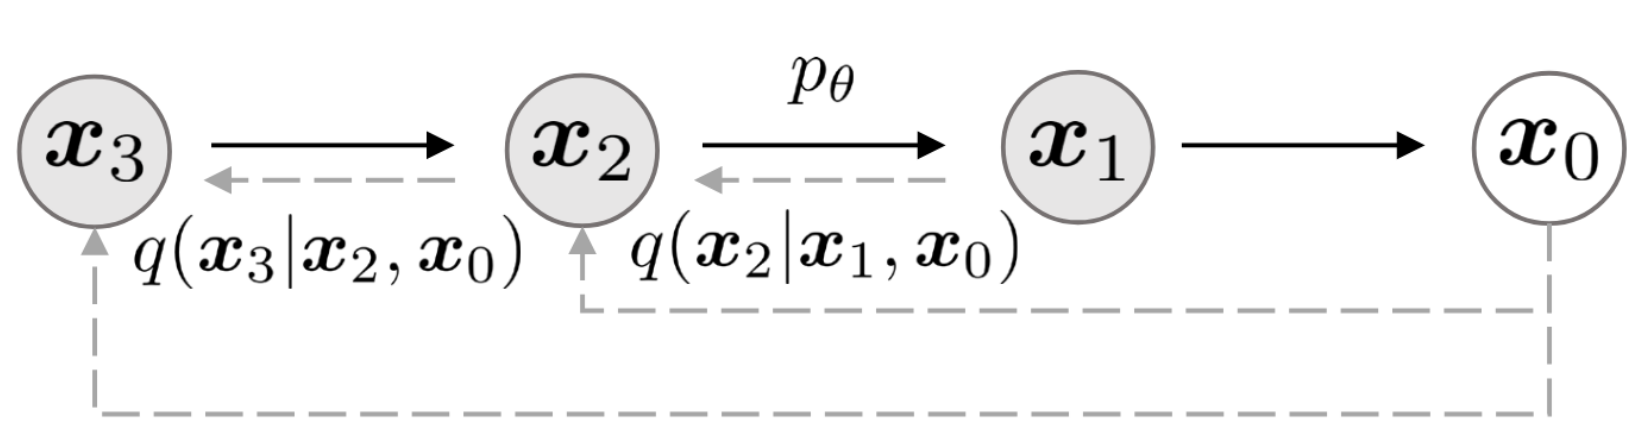

In [ ]:
# Saved figure from the previous semester; no execution needed.


To increase sampling speed, let us consider non-Markov forward process (encoder):

$$
q_\sigma(x_{1:T} \mid x_0) := q_\sigma(x_T \mid x_0) \prod_{t=2}^T q_\sigma(x_{t-1} \mid x_t, x_0),
$$

where terminal distribution is $q_\sigma(x_T \mid x_0) = \mathcal{N}\left(\sqrt{\bar{\alpha}_T} x_0, (1 - \bar{\alpha}_T) \mathbf{I} \right),$
and for all $ t > 1 $, the transitions are:
$$
q_\sigma(x_{t-1} \mid x_t, x_0) = \mathcal{N} \left(
\sqrt{\bar{\alpha}_{t-1}} x_0 + \sqrt{1 - \bar{\alpha}_{t-1} - \sigma_t^2} \cdot \frac{x_t - \sqrt{\bar{\alpha}_t} x_0}{\sqrt{1 - \bar{\alpha}_t}},
\; \sigma_t^2 \, \mathbf{I}
\right)
$$
**Note:**  
The mean function in $ q_\sigma(x_{t-1} \mid x_t, x_0) $ is carefully chosen to ensure that the marginal distribution remains consistent with the original forward process:
$$
q_\sigma(x_t \mid x_0) = \mathcal{N}\left( \sqrt{\bar{\alpha}_t} \, x_0, (1 - \bar{\alpha}_t) \, \mathbf{I} \right)
$$

The corresponding negative ELBO is:

$$
\mathbb{E}_{q_\sigma} \left[
\log q_\sigma(x_T \mid x_0) + \sum_{t=2}^{T} \log q_\sigma(x_{t-1} \mid x_t, x_0)
- \sum_{t=1}^{T} \log p_\theta^{(t)}(x_{t-1} \mid x_t)
- \log p_\theta(x_T)
\right]
$$

The construction preserves the noisy marginals used for training, so a DDPM noise predictor can be reused for DDIM sampling. This does not mean all weighted ELBOs are numerically identical. The sampling update is:

$$
x_{t-1} = 
\sqrt{\bar{\alpha}_{t-1}} 
\left(
\frac{x_t - \sqrt{1 - \bar{\alpha}_t} \epsilon_\theta^{(t)}(x_t)}{\sqrt{\bar{\alpha}_t}}
\right)
+
\sqrt{1 - \bar{\alpha}_{t-1} - \sigma_t^2} \cdot \epsilon_\theta^{(t)}(x_t)
+
\sigma_t \epsilon_t
$$

**Note:** when the noise schedule is set to $\sigma_t = \sqrt{\frac{1 - \bar{\alpha}_{t-1}}{1 - \bar{\alpha}_t}} \cdot \sqrt{1 - \frac{\bar{\alpha}_t}{\bar{\alpha}_{t-1}}},$
for all $t$, the forward process becomes **Markovian**, and the overall generative model reduces to a **DDPM**.



With $\sigma_t=0$, DDIM is deterministic given the initial noise. Faster sampling uses a subsequence of timesteps and the corresponding cumulative noise levels; it is not merely early stopping. The DDPM special case above uses posterior variance $\tilde\beta_t$.

Source: [Song et al., DDIM (2020)](https://arxiv.org/abs/2010.02502).

## Visual recap · From a digit to noise

The tiles are states of one simulated forward Markov chain on an MNIST digit. Teal arrows follow the chain; blue arrows indicate that training can sample any chosen noise level directly from $q(x_t\mid x_0)$. The shortcut has the correct marginal distribution; it need not reproduce the same individual trajectory.

**Takeaway:** training does not require running all the earlier forward steps.

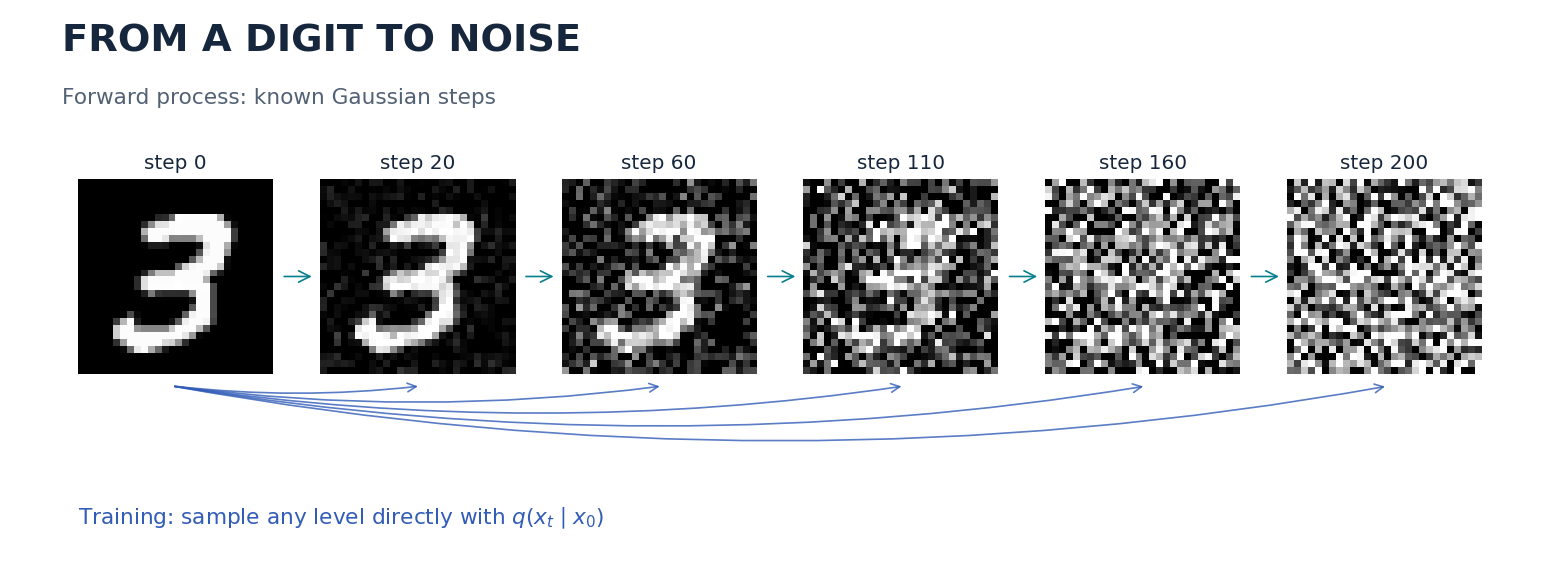

In [ ]:
# Saved illustration. Its executable source is in seminar7_ddpm_mnist.ipynb.
# View this output without running this cell.

## Visual recap · One model, two samplers

Both samplers query the same trained noise predictor. DDPM uses adjacent reverse transitions with fresh Gaussian noise (except at the final step). Deterministic DDIM ($\eta=0$) can visit a subset of noise levels without adding fresh noise.

**Takeaway:** change the sampling algorithm without retraining the network. The simplified schematic uses DDPM posterior variance; the implementation clips the clean-image estimate and recomputes the consistent noise estimate for DDIM.

Sources: [Ho et al., DDPM (2020)](https://arxiv.org/abs/2006.11239), [Song et al., DDIM (2020)](https://arxiv.org/abs/2010.02502).

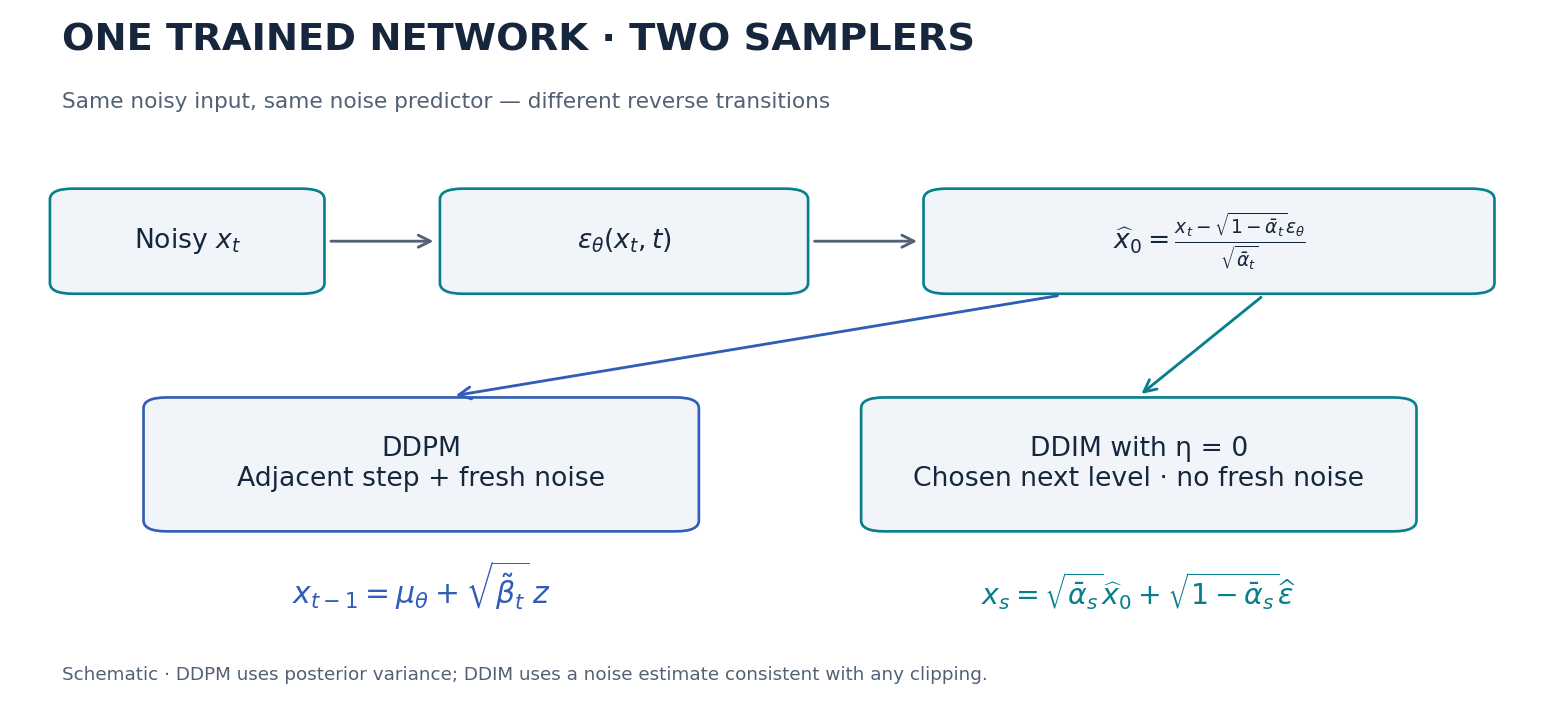

In [ ]:
# Saved illustration. Its executable source is in seminar7_ddpm_mnist.ipynb.
# View this output without running this cell.

## Visual recap · Randomness along the path

Actual trajectories from the practical model after 1,500 training updates. Each curve is a fixed scalar projection of the intermediate images. Start from one identical noise image, use 200 network calls, and change only the additional-noise seed.

**Takeaway:** DDPM can follow different paths; deterministic DDIM repeats the same path. The overlapping DDIM curves do not establish that the path must be smooth. Initial noise still supplies diversity in DDIM.

Continue with [the MNIST practice](seminar7_ddpm_mnist.ipynb): compare equal budgets first, then reduce DDIM to 50, 20 and 10 calls.

Each trajectory panel uses its own vertical scale.

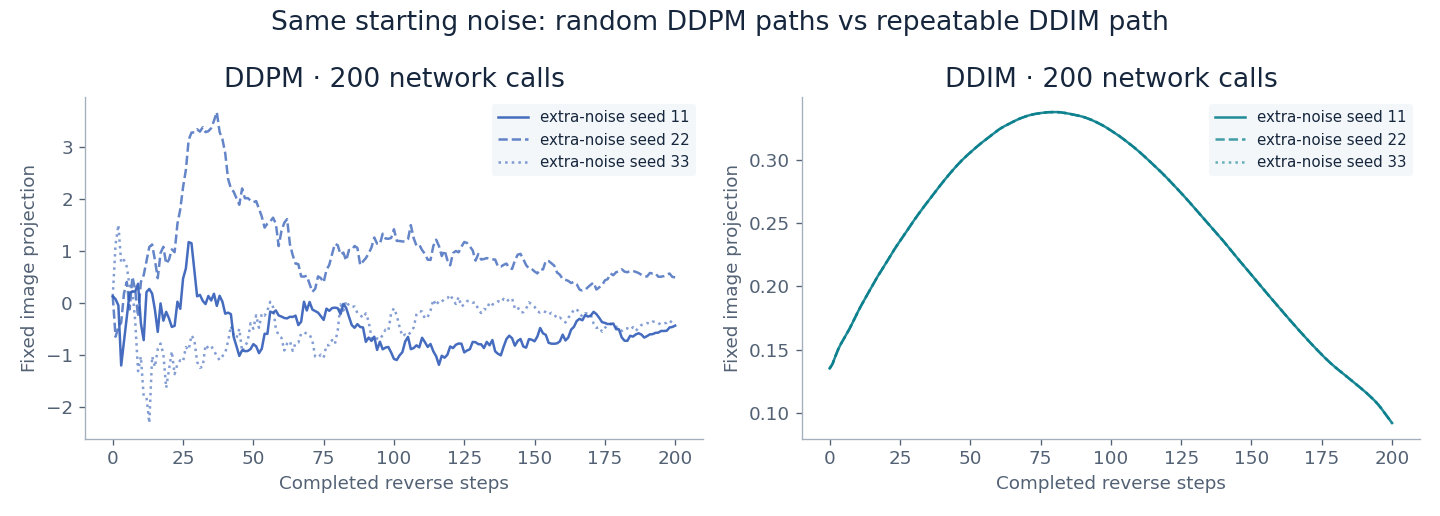

In [ ]:
# Saved illustration. Its executable source is in seminar7_ddpm_mnist.ipynb.
# View this output without running this cell.